## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Becca Hobson

**Date:** 10/21/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.

,Token,Frequency
0,new,1365
1,date,1202
2,get,1052
3,please,1022
4,enron,927
5,like,923
6,2002,869
7,would,806
8,one,798
9,message,795


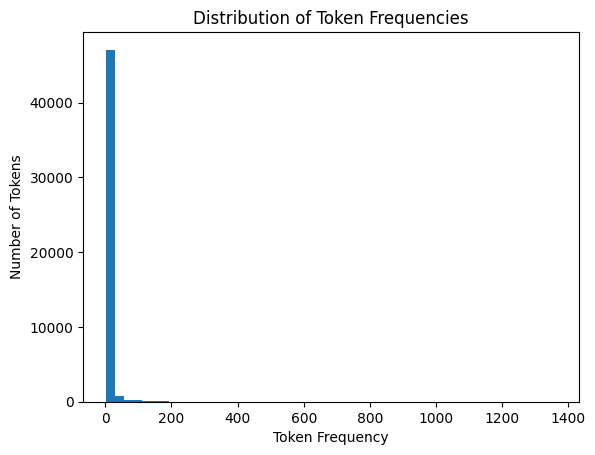

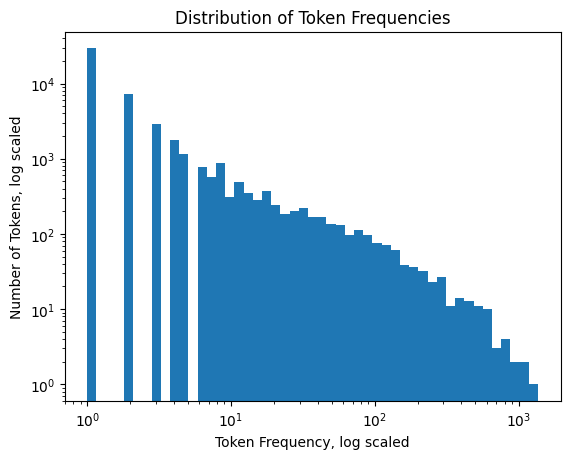

Total tokens: 276949
Unique tokens: 48691
Tokens appearing exactly once: 29404


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#Question 1
import pickle
from collections import Counter

with open('/content/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

token_count = Counter(all_tokens)
token_freq = token_count.most_common()

token_table = pd.DataFrame(token_freq[:20], columns=['Token', 'Frequency'])
display(token_table) #display the 20 most common tokens

frequencies = list(token_count.values())

plt.hist(frequencies, bins=50) #create histogram
plt.xlabel('Token Frequency')
plt.ylabel('Number of Tokens')
plt.title('Distribution of Token Frequencies')
plt.show() #difficult to interpret

plt.hist(frequencies, bins=np.logspace(0, np.log10(max(frequencies)), 50)) #create scaled histogram, easier to visualize data
plt.xscale('log')
plt.yscale('log') #scale both x and y axes using log
plt.xlabel('Token Frequency, log scaled')
plt.ylabel('Number of Tokens, log scaled')
plt.title('Distribution of Token Frequencies')
plt.show()

counts = np.array([c for _, c in token_freq])

print("Total tokens:", len(all_tokens))
print("Unique tokens:", len(token_count))
print("Tokens appearing exactly once:", (counts == 1).sum())


**1. Plot a histogram of the occurrences of tokens. What do you notice about the frequency of occurrence of different tokens? How does it look?**

Upon first making the histogram, the data was extremely skewed and very difficult to interpret, because of that I re plotted the histogram to be scaled along both the x and y axes. Scaling the histogram made the patterns easier to visualize the varaition in the data. Even then, the distribution of token frequencies is skewed strongly to the right, with a small number of tokens appearing very frequently and most of the tokens appearing very infrequently. There are 48,691 unique tokens, and 29,404 (~ 60.4%) appear only once. The three most frequent tokens are 'new', 'date', and 'get', each of which have frequencies of ~ 1,000. This suggests that the dataset contains a few commonly used words but a large number of rare words.

(18634, 2712)
   Email Type  new  date  get  please  enron  like  2002  would  one  ...  \
0           0    0     0    0       0      0     0     0      0    0  ...   
1           0    0     0    0       0      0     0     0      0    0  ...   
2           0    1     0    0       0      0     0     0      0    0  ...   
3           1    0     0    0       0      0     0     0      0    1  ...   
4           1    0     0    0       0      0     0     0      0    0  ...   

   ï¿½ï¿½  safety  yap  ypil  maintain  procedures  tip  elizabeth  \
0       0       0    0     0         0           0    0          0   
1       0       0    0     0         0           0    0          0   
2       0       0    0     0         0           0    0          0   
3       0       0    0     0         0           0    0          0   
4       0       0    0     0         0           0    0          0   

   leadership  italian  
0           0        0  
1           0        0  
2           0        0  
3 

,Coefficient
localized,0.776867
background-image:,-0.714570
thermal,0.664988
intervention,-0.664891
"helvetica,",0.583103
aging,0.539448
cnet,-0.527902
transcript,0.495305
form.,0.492922
xanaax,0.491739


Explained variance ratio: [0.01113077 0.00861218]
Total explained by 2 PCs: 0.019742957060158994


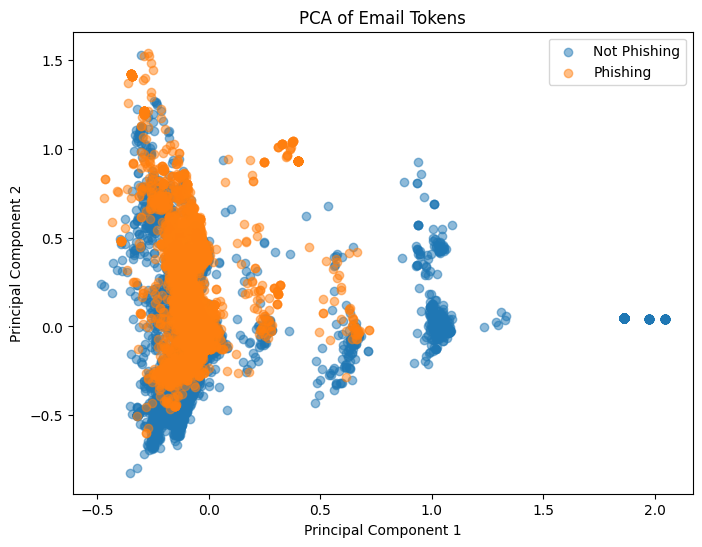

PCA Training R-squared: 0.7663772387962348
PCA Test R-squared: 0.6651623499283164


In [25]:
#Question 2, 3, and 4
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.decomposition import PCA

pdf = pd.read_parquet('/content/Phishing_clean.parquet')

#Question 2
print(pdf.shape)
print(pdf.head()) #inspecting data

X = pdf.drop(columns=['Email Type']) #define features and target variable
y = pdf['Email Type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=53, stratify=y) #80/20 train test split
print(X_train.shape, X_test.shape) #print data shape

ols = LinearRegression()
ols.fit(X_train, y_train) #it linear regression on training data

print('Training R squared:', r2_score(y_train, ols.predict(X_train))) #calculate R squared for training set
print('Test R squared:', r2_score(y_test, ols.predict(X_test))) #calculate R squared for test set

coefficients = pd.Series(ols.coef_, index=X.columns) #pair each regression coefficient w its corresposnding token

top = coefficients.reindex(coefficients.abs().sort_values(ascending=False).index).head(20) #find 20 tokens w the largest absolute coefficents

display(top.to_frame(name='Coefficient')) #display results as a table

#Question 3
pca2 = PCA(n_components=2)
X_pca = pca2.fit_transform(X)

print('Explained variance ratio:', pca2.explained_variance_ratio_)
print('Total explained by 2 PCs:', pca2.explained_variance_ratio_.sum())

pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2']) #create dataframe for plotting
pca_df['Email Type'] = y.to_numpy()

#Create Scatter Plot
plt.figure(figsize=(8,6))
plt.scatter(pca_df.loc[pca_df['Email Type'] == 0, 'PC1'], pca_df.loc[pca_df['Email Type'] == 0, 'PC2'], alpha=0.5, label='Not Phishing')
plt.scatter(pca_df.loc[pca_df['Email Type'] == 1, 'PC1'], pca_df.loc[pca_df['Email Type'] == 1, 'PC2'], alpha=0.5, label='Phishing')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Email Tokens')
plt.legend()
plt.show()

#Question 4
pca = PCA(n_components=2610) #perform PCA using 2610 principal components

X_train_pca = pca.fit_transform(X_train) #fit PCA on training data and transform both datasets
X_test_pca = pca.transform(X_test)

pca_model = LinearRegression() #fit linear regression using the principal components
pca_model.fit(X_train_pca, y_train)

print('PCA Training R-squared:', r2_score(y_train, pca_model.predict(X_train_pca))) #calculate train R squared
print('PCA Test R-squared:', r2_score(y_test, pca_model.predict(X_test_pca))) #calculate test R squared



**2. Run a regression of 𝑦 on the one-hot-encoded emails. What is the 𝑅2 on the test set? On the training set? What words have the largest coefficients in absolute value and most strongly influence predictions?**

The training R squared = 0.767 and the test R squared = 0.666, suggesting that the model performs better on training data than when its presented with new emails (test data). This also suggests that the model may be slightly overfitted to the training data. The words with the largest absolute coefficents were 'localized', 'background image', 'thermal' and 'intervention'. The positive coefficients are associated with phishing emails, while negative coefficients are associated with non phishing emails.

**3. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?**

The PCA scatter plot shows a very signifigant amount of overlap between phishing and non phishing emails, which is heavily concentrated on the left side of the graph. The scatter plot seems to show some vertically linear patterns in its clustering. There are also a decent amount of non phishing data points forming clusters on the right side of the grpah. Ultimately, it seems that the first two principal components alone are not able to clearly separate between phishing and non phishing emails. The scatter plot captures a very small amount of variation (less than 2%).

**4. What is the R2 on the training and test sets? How does this performance compare to the linear regression?**

The R squared on the training set was 0.766 and the R squared on the test set was 0.665, both of which are very simialr to the values from question 2. The two models perform almost the same, with the PCA model performing just barely worse than the linear regression model.

**5. Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.**

The main advantage of using principal components for a high dimensional regression is that PCA compresses the problem, reducing the number of directions, while still being able to capture a large enough amount of variation within the data. Where the orginal data has many correlated features or information that is not unique, PCA is able to combine them. Although, in this scenario PCA was not very beneficial as the number of features was not reduced significantly, and the R squared values stayed pretty much the same.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]